# Early dropout sur Fashion-MNIST (MLP et CNN)

Papier : *Dropout Reduces Underfitting* (Liu et al., ICML 2023). L'idée : mettre du dropout seulement au **début** de l'entraînement puis le couper (early dropout) aiderait les modèles qui **sous-apprennent**. Le papier le montre sur ImageNet avec des modèles de 5 à 20 M de paramètres, et reste flou sur ce que "début" veut dire.

Nous on teste ça sur des modèles du cours, 100 à 1000 fois plus petits, avec deux questions :
- **Q1** : est-ce que l'early dropout marche à notre échelle, et sur quels modèles ?
- **Q2** : quelle durée de dropout est la bonne ? Est-ce vraiment sans importance comme le dit le papier (de 1 % à 50 % de l'entraînement) ?
- **Q3** : le "début" se compte-t-il en epochs ou en itérations (pas de gradient) ?

La démarche, dans l'ordre du notebook :
1. **Calibration** : trouver pour chaque modèle un réglage (largeur, nb d'epochs) où il sous-apprend, sinon le papier ne prédit rien. Puis confirmer ce régime sur des seeds qui n'ont pas servi à le choisir.
2. **Grille principale** : dans ce réglage, tester plusieurs durées d'early dropout sur 5 seeds (10 pour le CNN, plus bruité), puis vérifier ce que valent les résultats (puissance, correction pour comparaisons multiples).
3. **Budget plus court** : voir si le résultat dépend du nombre d'epochs.
4. **Contrôle** : vérifier que dans un réglage qui surapprend on trouve bien l'inverse.
5. **Sensibilité** : refaire à p = 0.3 (le taux utilisé par le groupe CIFAR-10), et avec un seul dropout avant la sortie (leur position).
6. **Epochs ou itérations** : refaire la grille avec un batch 4 fois plus petit et 4 fois plus grand.

Chaque run est sauvegardé en CSV dans `resultats/`. Les runs déjà faits sont sautés, donc relancer tout le notebook prend quelques secondes : il relit juste les CSV.

In [167]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import datasets

# from google.colab import drive
# drive.mount("/content/drive")
# os.chdir("/content/drive/MyDrive/early-dropout")


from config import BATCH, P, EARLY_GRID      # 128, 0.1, [0, 0.05, 0.1, 0.2, 0.3, 0.5, 1]
from models import mlp, cnn
from train import entrainer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## Le protocole (fixé avant de regarder les résultats)

Tout est identique d'un run à l'autre, sauf ce qu'on étudie (la durée du dropout) :

| Choix | Valeur | Pourquoi |
|---|---|---|
| Optimiseur | Adam, lr 1e-3, pas de weight decay | le plus standard, et pas d'autre régularisation qui se mélange au dropout |
| Schedule | cosinus jusqu'à 0, sans warmup | le lr suit le même chemin quel que soit le dropout (pas le cas avec ReduceLROnPlateau) |
| Batch | 128 | |
| Augmentation | aucune | sinon le sous-apprentissage viendrait de l'augmentation et pas du modèle |
| Dropout | p = 0.1, après chaque couche cachée (MLP) ou chaque bloc (CNN) | taux de base du papier pour les petits modèles |
| Early dropout | p constant pendant `frac` × epochs, puis 0 | le plus simple à décrire ; le papier montre que constant ou linéaire donnent pareil (Tab. 3b) |
| Validation | 10 000 images tirées du train (seed 0) | tous les choix se font dessus, le test sert juste au chiffre final |
| Seeds | 5 (2 pour la calibration, 5 seeds neuves pour confirmer le régime, 10 pour la grille du CNN) | une même seed = mêmes poids de départ, donc on compare seed par seed |
| Valeur d'un run | moyenne des 5 dernières epochs | lisse le bruit d'une epoch à l'autre |

`frac` = durée du dropout en fraction du nombre d'epochs : 0 = sans dropout, 1 = dropout classique (tout le long), entre les deux = early dropout.

Les mesures (loss et accuracy) sont toujours faites sans dropout, en mode eval. La loss d'entraînement est mesurée sur 10 000 images fixes du train.

In [168]:
tr = datasets.FashionMNIST("./data", train=True, download=True)
te = datasets.FashionMNIST("./data", train=False, download=True)
Xtr, Xte = tr.data.float().unsqueeze(1) / 255, te.data.float().unsqueeze(1) / 255     # (N, 1, 28, 28)
ytr, yte = tr.targets, te.targets

# validation : 10 000 images du train, toujours les mêmes
perm = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))
Xva, yva = Xtr[perm[:10000]], ytr[perm[:10000]]
Xtr, ytr = Xtr[perm[10000:]], ytr[perm[10000:]]

# normalisation avec les stats du train uniquement
mu, sd = Xtr.mean(), Xtr.std()
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd

images = {k: v.to(device) for k, v in dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte).items()}   # pour le CNN
vecteurs = {k: (v.flatten(1) if k.startswith("X") else v) for k, v in images.items()}                        # pour le MLP (784)
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


## Les 3 petites fonctions du notebook

Pour ne pas recopier la même boucle partout :
- `lancer` : fait **un run** et l'écrit dans un CSV (ou ne fait rien si le CSV existe déjà). L'entraînement lui-même est dans `train.py` (`entrainer`).
- `tableau_calibration` : pour chaque (largeur, epochs), compare sans dropout et dropout classique.
- `gains` : pour chaque durée, la différence avec le run sans dropout, seed par seed, avec un intervalle de confiance.

In [169]:
# un "cadre" = un modèle + ses données. L est la largeur (neurones par couche pour le MLP, canaux du 1er bloc pour le CNN)
CADRES = {
    "mlp_fmnist": (lambda L: mlp(784, 10, couche_cache=L), vecteurs),
    "cnn_fmnist": (lambda L: cnn(1, 10, largeur=L), images),
}

def fichier(cadre, L, E, frac, seed, dossier="resultats"):
    return f"{dossier}/{cadre}_w{L}_e{E}_frac{frac}_s{seed}.csv"

def lancer(cadre, L, E, frac, seed, p=P, dossier="resultats"):
    f = fichier(cadre, L, E, frac, seed, dossier)
    if os.path.exists(f):
        return                                   # déjà fait
    creer, data = CADRES[cadre]
    torch.manual_seed(seed)                      # même seed = mêmes poids de départ
    model, opt = creer(L)
    model.to(device)
    hist = entrainer(model, opt, data, E, t_early=round(frac * E), p=p, batch=BATCH)
    hist.assign(cadre=cadre, width=L, epochs=E, frac=frac, seed=seed).to_csv(f, index=False)
    print(f, " val acc", round(hist.val_acc.tail(5).mean(), 4))

In [170]:
def tableau_calibration(cadre, largeurs, budgets, seeds=[0, 1]):
    lignes = []
    for L in largeurs:
        for E in budgets:
            sans = [pd.read_csv(fichier(cadre, L, E, 0, s)) for s in seeds]      # sans dropout
            avec = [pd.read_csv(fichier(cadre, L, E, 1, s)) for s in seeds]      # dropout classique
            # delta = acc val (dropout classique) - acc val (sans dropout), en points, pour chaque seed
            delta = [100 * (a.val_acc.tail(5).mean() - b.val_acc.tail(5).mean()) for a, b in zip(avec, sans)]
            lignes.append({
                "largeur": L, "epochs": E,
                "acc_sans_dropout": np.mean([d.val_acc.tail(5).mean() for d in sans]),
                "delta_moy": np.mean(delta),
                "delta_max": max(delta),          # la seed la moins négative
                # de combien la val loss remonte entre son minimum et la fin du run
                "remontee_val_loss": np.mean([d.val_loss.tail(5).mean() / d.val_loss.min() - 1 for d in sans]),
            })
    tab = pd.DataFrame(lignes).set_index(["largeur", "epochs"])
    tab["sous_apprentissage"] = tab.delta_max <= -0.5                          # toutes les seeds perdent au moins 0.5 pt
    tab["acc_ok"] = tab.acc_sans_dropout >= 0.9 * tab.acc_sans_dropout.max()   # le modèle apprend quand même
    tab["valide"] = tab.sous_apprentissage & tab.acc_ok & (tab.remontee_val_loss < 0.02)
    return tab.round(3)

In [171]:
T95 = {2: 12.71, 3: 4.30, 5: 2.78, 10: 2.26}       # quantile de Student à 95 % selon le nb de seeds
METRIQUES = ["train_loss", "val_loss", "val_acc", "test_acc"]

def fin_de_run(f):
    return pd.read_csv(f).tail(5)[METRIQUES].mean()        # moyenne des 5 dernières epochs

def gains(cadre, L, E, fracs, seeds, dossier="resultats", reference=None, dossier_ref="resultats"):
    # pour chaque durée : (run avec dropout) - (run sans dropout de la même seed), puis moyenne et IC sur les seeds
    reference = reference or cadre
    lignes = {}
    for frac in fracs:
        d = pd.DataFrame([fin_de_run(fichier(cadre, L, E, frac, s, dossier)) - fin_de_run(fichier(reference, L, E, 0, s, dossier_ref))
                          for s in seeds])
        d[["val_acc", "test_acc"]] *= 100                  # accuracy en points
        ic = T95[len(seeds)] * d.std() / len(seeds) ** 0.5
        lignes[frac] = pd.concat([d.mean(), ic.add_prefix("ic_")])
    colonnes = [c for m in METRIQUES for c in (m, "ic_" + m)]
    return pd.DataFrame(lignes).T[colonnes].round(3)

def niveaux(cadre, L, E, fracs, seeds):
    # valeur moyenne de chaque métrique sur les seeds (et son écart-type), pour chaque durée ; accuracy en %
    lignes = {}
    for frac in fracs:
        d = pd.DataFrame([fin_de_run(fichier(cadre, L, E, frac, s)) for s in seeds])
        d[["val_acc", "test_acc"]] *= 100
        lignes[frac] = pd.concat([d.mean(), d.std().add_prefix("sd_")])
    colonnes = [c for m in METRIQUES for c in (m, "sd_" + m)]
    return pd.DataFrame(lignes).T[colonnes].round(3)

**Comment lire un tableau de `gains`** : une ligne par durée de dropout. `train_loss`, `val_loss` = écart de loss avec le run sans dropout (négatif = mieux). `val_acc`, `test_acc` = écart d'accuracy en points (positif = mieux). Les colonnes `ic_` donnent la demi-largeur de l'intervalle de confiance à 95 % : **l'effet est significatif si le gain est plus grand que son `ic`** (en valeur absolue). Sinon on ne peut pas le distinguer du bruit entre seeds.

Avec 5 seeds on ne voit que les effets assez gros, et on regarde beaucoup de lignes sans corriger : un "significatif" isolé peut être un hasard, on se fie aux tendances qui se répètent.

---
## 1. Calibration : trouver un réglage où le modèle sous-apprend

Le papier ne prédit un gain que si le modèle sous-apprend. Il faut donc le vérifier et pas le supposer. On utilise le critère du papier comme thermomètre : on entraîne le même modèle sans dropout puis avec dropout classique, et on regarde

> delta = accuracy val (dropout classique) − accuracy val (sans dropout)

Le dropout classique enlève de la capacité au modèle. Si le modèle surapprend ça l'aide (delta > 0). S'il manque déjà de capacité ça le pénalise (delta < 0) : c'est le sous-apprentissage qu'on cherche.

Une case (largeur, epochs) est **valide** si :
1. toutes les seeds perdent au moins 0.5 pt (`delta_max ≤ -0.5`) ;
2. l'accuracy sans dropout fait au moins 90 % de la meilleure de la grille (sinon on étudie un modèle qui n'apprend rien) ;
3. la val loss sans dropout remonte de moins de 2 % à la fin (sinon il commence déjà à surapprendre).

Parmi les cases valides on prend **le budget le plus long**, puis la plus grande largeur. Le budget long, c'est pour que le modèle ait fini de converger : sinon un gain pourrait juste vouloir dire "ça va plus vite", pas "ça arrive à un meilleur point".

### MLP (2 couches cachées)

In [172]:
for L in [16, 32, 64]:
    for E in [10, 20, 50]:
        for frac in [0, 1]:
            for seed in [0, 1]:
                lancer("mlp_fmnist", L, E, frac, seed)

tableau_calibration("mlp_fmnist", [16, 32, 64], [10, 20, 50])

acc_sans_dropout  delta_moy  delta_max  remontee_val_loss  \
largeur epochs                                                              
16      10                 0.856     -0.780     -0.592              0.012   
        20                 0.863     -0.989     -0.820              0.003   
        50                 0.868     -1.110     -0.982              0.001   
32      10                 0.869     -0.271     -0.156              0.018   
        20                 0.879     -0.460     -0.448              0.003   
        50                 0.883     -0.370     -0.166              0.062   
64      10                 0.880     -0.300     -0.282              0.020   
        20                 0.889     -0.250     -0.204              0.004   
        50                 0.888      0.275      0.438              0.265   

                sous_apprentissage  acc_ok  valide  
largeur epochs                                      
16      10                    True    True    True  
        20                    True    True    True  
        50                    True    True    True  
32      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False  
64      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False

C'est la largeur qui décide du régime : seul le MLP à 16 neurones perd nettement avec le dropout classique (≈ -1 pt), à tous les budgets. À 32 neurones la perte est trop petite (≈ -0.4 pt), et à 64 neurones sur 50 epochs le dropout se met à aider (≈ +0.3 pt) pendant que la val loss remonte de plus de 25 % : ce réglage surapprend, on s'en servira comme **contrôle**.

→ On retient **MLP largeur 16, 50 epochs** (13 000 paramètres).

### CNN (3 blocs conv-conv-maxpool)

In [173]:
for L in [4, 8, 16]:
    for E in [10, 20, 50]:
        for frac in [0, 1]:
            for seed in [0, 1]:
                lancer("cnn_fmnist", L, E, frac, seed)

tableau_calibration("cnn_fmnist", [4, 8, 16], [10, 20, 50])

acc_sans_dropout  delta_moy  delta_max  remontee_val_loss  \
largeur epochs                                                              
4       10                 0.804     -1.436     -0.842              0.023   
        20                 0.840     -0.645      0.070              0.006   
        50                 0.876     -1.780     -1.140              0.000   
8       10                 0.860     -0.966     -0.366              0.043   
        20                 0.891     -0.737     -0.514              0.011   
        50                 0.908      0.102      0.106              0.015   
16      10                 0.887     -0.003      0.272              0.047   
        20                 0.911      0.021      0.232              0.010   
        50                 0.915      0.904      1.166              0.652   

                sous_apprentissage  acc_ok  valide  
largeur epochs                                      
4       10                    True   False   False  
        20                   False    True   False  
        50                    True    True    True  
8       10                   False    True   False  
        20                    True    True    True  
        50                   False    True   False  
16      10                   False    True   False  
        20                   False    True   False  
        50                   False    True   False

Même logique que le MLP et que la Fig. 5 du papier : plus le modèle est petit, plus le dropout classique le pénalise ; plus il est gros et entraîné longtemps, plus il l'aide. Deux cases sont valides : largeur 4 à 50 epochs et largeur 8 à 20 epochs. La largeur 4 à 10 epochs sous-apprend aussi mais son accuracy est trop basse (critère 2).

→ D'après la règle (budget le plus long) on retient **CNN largeur 4, 50 epochs** (4 700 paramètres). La largeur 8 à 20 epochs (limite, voir l'étape 3) servira de deuxième point à l'étape 3, et la largeur 16 à 50 epochs (delta +0.9 pt, val loss qui remonte de 65 %) de **contrôle**.

### Confirmation du régime sur des graines neuves

Le régime a été choisi avec les seeds 0 et 1, qui font aussi partie des 5 seeds de la grille. Si ces deux seeds avaient perdu un peu plus que la normale par hasard, elles auraient poussé à choisir ce réglage, et elles gonfleraient ensuite la confirmation (régression vers la moyenne). On remesure donc "sans dropout contre dropout classique" sur 5 seeds qui n'ont servi à rien (5 à 9), puis sur les 10 seeds ensemble.

In [174]:
GRAINES_NEUVES = [5, 6, 7, 8, 9]
for seed in GRAINES_NEUVES:
    for frac in [0, 1]:
        lancer("mlp_fmnist", 16, 50, frac, seed)
        lancer("cnn_fmnist", 4, 50, frac, seed)

pd.concat({
    "MLP, seeds 5-9": gains("mlp_fmnist", 16, 50, [1], GRAINES_NEUVES),
    "MLP, seeds 0-9": gains("mlp_fmnist", 16, 50, [1], list(range(10))),
    "CNN, seeds 5-9": gains("cnn_fmnist", 4, 50, [1], GRAINES_NEUVES),
    "CNN, seeds 0-9": gains("cnn_fmnist", 4, 50, [1], list(range(10))),
})

,,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
"MLP, seeds 5-9",1,0.041,0.003,0.026,0.011,-0.895,0.400,-0.604,0.123
"MLP, seeds 0-9",1,0.040,0.002,0.025,0.005,-0.995,0.194,-0.646,0.128
"CNN, seeds 5-9",1,0.016,0.013,0.000,0.017,-0.394,0.657,-0.330,0.609
"CNN, seeds 0-9",1,0.026,0.013,0.013,0.014,-0.903,0.644,-0.719,0.541


- **MLP : régime confirmé.** Sur les seeds neuves le dropout classique fait toujours perdre (≈ -0.9 pt en validation, -0.6 en test, IC entièrement négatif, 5 seeds sur 5). C'est un peu moins que sur les seeds 0-4 (-1.1) : la petite régression vers la moyenne attendue, rien de plus.
- **CNN : régime limite.** Sur les seeds neuves la perte tombe à ≈ -0.4 pt, avec un IC qui contient 0. Sur les 10 seeds ensemble elle reste négative (≈ -0.9 pt, IC entièrement négatif), mais seule une seed sur deux perd au moins 0.5 pt : avec notre règle appliquée à 10 seeds, la case ne serait plus valide. Le CNN largeur 4 est donc **à la limite** du sous-apprentissage, et l'absence d'effet de l'early dropout sur ce modèle est moins parlante que pour le MLP.

---
## 2. Grille principale : quelle durée de dropout ?

Dans les deux réglages retenus, on teste toutes les durées de `EARLY_GRID` sur 5 seeds (10 pour le CNN, voir plus bas), plus une durée encore plus courte (0.02 = 1 epoch) : notre meilleur point était d'abord la durée la plus courte testée, on regarde si c'est encore mieux en dessous. À 50 epochs ça fait 1, 2, 5, 10, 15 et 25 epochs de dropout (le 0.05 donne 2 epochs car python arrondit 2.5 à 2).

In [175]:
SEEDS = [0, 1, 2, 3, 4]
DUREES = [0.02] + EARLY_GRID[1:]          # 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1

for frac in [0] + DUREES:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 50, frac, seed)
        lancer("cnn_fmnist", 4, 50, frac, seed)

g_mlp = gains("mlp_fmnist", 16, 50, DUREES, SEEDS)
g_mlp

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.02,-0.009,0.005,0.003,0.006,-0.079,0.293,0.126,0.433
0.05,-0.013,0.006,0.004,0.006,0.048,0.245,0.130,0.332
0.10,-0.011,0.002,0.008,0.006,-0.106,0.326,0.119,0.438
0.20,-0.006,0.004,0.009,0.005,-0.220,0.323,-0.062,0.386
0.30,-0.001,0.003,0.011,0.006,-0.378,0.383,-0.096,0.307
0.50,0.012,0.003,0.015,0.006,-0.670,0.415,-0.334,0.093
1.00,0.039,0.004,0.024,0.007,-1.095,0.238,-0.687,0.301


In [ ]:
# le CNN varie beaucoup d'une seed à l'autre (IC d'environ ±1 pt avec 5 seeds) : on lui ajoute les 5 seeds neuves (5 à 9)
SEEDS_CNN = list(range(10))
for frac in DUREES:
    for seed in SEEDS_CNN[5:]:
        lancer("cnn_fmnist", 4, 50, frac, seed)

g_cnn = gains("cnn_fmnist", 4, 50, DUREES, SEEDS_CNN)
g_cnn

In [ ]:
# les mêmes tableaux en figure : gain par rapport à "sans dropout" selon la durée, barres = IC à 95 %
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
titres = {"train_loss": "écart loss d'entraînement (négatif = mieux)",
          "val_loss": "écart loss de validation (négatif = mieux)",
          "val_acc": "gain accuracy validation (points)",
          "test_acc": "gain accuracy test (points)"}
for ligne, (nom, g) in enumerate([("MLP largeur 16 (5 seeds)", g_mlp), ("CNN largeur 4 (10 seeds)", g_cnn)]):
    for ax, m in zip(axes[ligne], titres):
        ax.errorbar(range(len(g)), g[m], yerr=g["ic_" + m], marker="o", capsize=4)
        ax.axhline(0, color="gray", lw=1)
        ax.set_xticks(range(len(g)))
        ax.set_xticklabels(g.index)
        ax.set_title(f"{nom} — {titres[m]}", fontsize=10)
        ax.set_xlabel("durée (fraction des 50 epochs), 1 = classique")
plt.tight_layout(); plt.show()

On choisit et on interprète sur la validation ; le test sert de vérification et va dans le même sens, avec des IC du même ordre.

**D'abord le régime (ligne 1.0)** : le dropout classique fait bien perdre, -1.1 pt de validation sur le MLP (5 seeds) et -0.9 pt sur le CNN (10 seeds, IC entièrement négatif).

**MLP** :
- Un early dropout **court** (1 à 10 epochs) fait baisser la loss d'entraînement finale de façon significative, sur les 5 seeds. C'est exactement ce qu'annonce le papier : le modèle apprend mieux ses données.
- De 1 à 5 epochs l'effet est comparable (≈ -0.01, avec un maximum ponctuel à 2 epochs), puis il diminue quand on allonge. On ne peut pas départager 1, 2 et 5 epochs : leurs IC se recouvrent.
- Mais ça ne se voit **pas sur l'accuracy** : aucun gain significatif en validation ni en test. Et la loss de validation **monte** un peu (+0.008 à 10 %, significatif).
- L'effet dépend beaucoup de la durée : plus c'est court mieux c'est, à 30 % il n'y a plus rien, et à partir de 50 % ça se comporte comme du dropout classique (tout se dégrade). Le papier dit que la durée compte peu entre 1 % et 50 % : chez nous ce n'est pas vrai.

**CNN (10 seeds)** :
- Les durées très courtes (1 et 2 epochs) ne font rien : écarts nuls sur toutes les mesures.
- Une baisse de loss d'entraînement apparaît pour des durées plus longues, 10 et 15 epochs (≈ -0.013, IC entièrement négatif, 7 à 8 seeds sur 10), et la loss de validation baisse un peu aussi (à la limite). C'est la même direction que sur le MLP, mais pas aux mêmes durées : sur le CNN, "early" voudrait plutôt dire 20 à 30 % de l'entraînement.
- Toujours aucun gain d'accuracy significatif (au mieux +0.2 pt à 20 %, IC ±0.5 pt).
- Les seeds restent très dispersées, et les deux moitiés ne disent pas la même chose : sur les seeds 0-4 rien n'est visible, sur les seeds 5-9 la baisse de loss d'entraînement est nette dès 5 epochs et l'accuracy monte d'environ 0.5 pt à 20 %. C'est pour ça qu'on ne conclut que sur les 10 seeds ensemble.

### Ce que valent ces résultats : puissance et comparaisons multiples

Deux vérifications, sans nouveau run :
- **Puissance** : avec nos seeds (5 pour le MLP, 10 pour le CNN), quelle taille d'effet avait-on de bonnes chances de voir ? Ça dit ce que vaut un résultat **non significatif** : "pas de gain de plus de X pt" n'a de sens que si X est petit. Calcul : effet minimal détectable ≈ (t à 97.5 % + t à 80 %) × écart-type des différences / √n, avec n le nombre de seeds. C'est le plus petit effet qu'on détecte 8 fois sur 10.
- **Correction de Holm** : chaque IC à 95 % a 5 % de chances d'être "significatif" par hasard, et on regarde beaucoup de lignes. Ça dit ce que vaut un résultat **significatif**. On classe les p-values (test de Student apparié, le même que les IC) de la plus petite à la plus grande ; la 1re doit être sous 0.05/k, la 2e sous 0.05/(k-1), etc., et on s'arrête au premier échec. On l'applique à la **mesure principale fixée d'avance**, la loss d'entraînement (c'est ce qu'annonce le papier) ; l'accuracy reste une mesure secondaire, exploratoire.

In [ ]:
from scipy import stats

EARLY = DUREES[:-1]                                                  # les durées early (sans le dropout classique)
MODELES = [("mlp_fmnist", 16, SEEDS), ("cnn_fmnist", 4, SEEDS_CNN)]   # 5 seeds pour le MLP, 10 pour le CNN

def differences(cadre, L, E, frac, seeds, metrique):
    # (run avec dropout) - (run sans dropout), seed par seed
    d = np.array([fin_de_run(fichier(cadre, L, E, frac, s))[metrique]
                  - fin_de_run(fichier(cadre, L, E, 0, s))[metrique] for s in seeds])
    return d * 100 if "acc" in metrique else d       # accuracy en points

lignes = []
for cadre, L, seeds in MODELES:
    n = len(seeds)
    facteur = stats.t.ppf(0.975, n - 1) + stats.t.ppf(0.80, n - 1)    # 2.78 + 0.94 avec 5 seeds, 2.26 + 0.88 avec 10
    ligne = {"modele": cadre, "seeds": n}
    for m in ["train_loss", "val_acc", "test_acc"]:
        sd = np.mean([differences(cadre, L, 50, f, seeds, m).std(ddof=1) for f in EARLY])
        ligne[m] = facteur * sd / n ** 0.5
    lignes.append(ligne)
print("Effet minimal détectable (loss, accuracy en points) :")
pd.DataFrame(lignes).set_index("modele").round(3)

In [ ]:
lignes = []
for cadre, L, seeds in MODELES:
    for frac in EARLY:
        d = differences(cadre, L, 50, frac, seeds, "train_loss")
        lignes.append({"modele": cadre, "frac": frac, "ecart_train_loss": d.mean(),
                       "p": stats.ttest_1samp(d, 0).pvalue})

holm = pd.DataFrame(lignes).sort_values("p").reset_index(drop=True)
holm["seuil_holm"] = 0.05 / (len(holm) - holm.index)            # 0.05/k, 0.05/(k-1), ...
holm["significatif"] = (holm.p <= holm.seuil_holm).cummin()     # on s'arrête au premier échec
holm.round(4)

**Puissance** : sur le MLP (5 seeds) on aurait vu un effet d'accuracy d'environ 0.45 pt. On peut donc dire qu'il n'y a pas de gain de cette taille, mais un gain de 0.2-0.3 pt (l'ordre de grandeur du papier) pourrait nous échapper. Sur le CNN, même avec 10 seeds, le seuil est d'environ 0.7 pt en validation et 0.55 pt en test (il était de 1.1 à 1.3 pt avec 5 seeds) : l'absence de gain d'accuracy y reste une conclusion plus faible que sur le MLP. La baisse de loss d'entraînement du MLP (≈ -0.013) est plus de deux fois au-dessus de son seuil (≈ 0.005) ; celle du CNN (≈ -0.014) est tout juste à son seuil (≈ 0.014).

**Holm** (12 comparaisons sur la loss d'entraînement) : la baisse pour un early de 2 et 5 epochs sur le MLP reste significative, ainsi que la hausse à 25 epochs. 1 epoch échoue de justesse. Sur le CNN, la baisse à 10 epochs (20 %) échoue de peu (p ≈ 0.008 pour un seuil de 0.006) : c'est un indice, pas un résultat établi. Le résultat principal du MLP n'est donc pas un faux positif dû au nombre de tests.

### Les courbes : est-ce que les modèles surapprennent ?

Loss d'entraînement (pointillés) et de validation (trait plein) sur le même graphe, moyennées sur les 5 seeds. Un modèle **surapprend** quand sa loss de validation **remonte** alors que celle d'entraînement continue de baisser. Un écart entre les deux courbes ne suffit pas : il y en a toujours un, puisque le modèle est meilleur sur les images qu'il a vues.

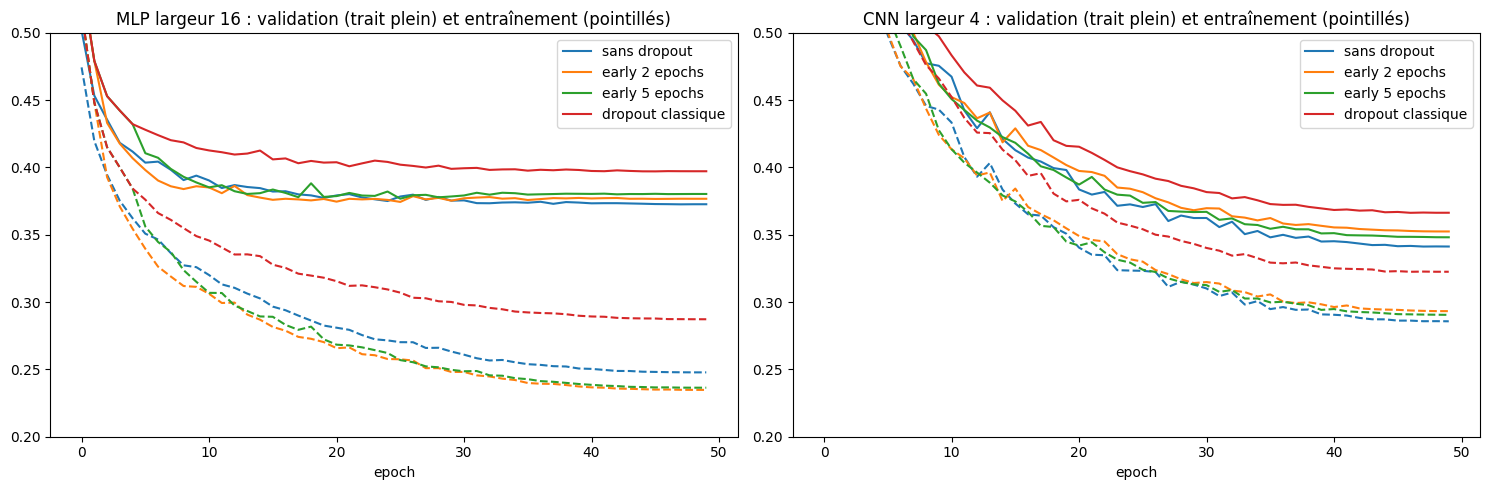

mlp_fmnist sans dropout       minimum de la val loss à l'epoch 47, remontée à la fin : 0.03 %
mlp_fmnist early 2 epochs     minimum de la val loss à l'epoch 25, remontée à la fin : 0.62 %
mlp_fmnist early 5 epochs     minimum de la val loss à l'epoch 25, remontée à la fin : 0.94 %
mlp_fmnist dropout classique  minimum de la val loss à l'epoch 45, remontée à la fin : 0.03 %
cnn_fmnist sans dropout       minimum de la val loss à l'epoch 47, remontée à la fin : 0.05 %
cnn_fmnist early 2 epochs     minimum de la val loss à l'epoch 49, remontée à la fin : 0.07 %
cnn_fmnist early 5 epochs     minimum de la val loss à l'epoch 49, remontée à la fin : 0.06 %
cnn_fmnist dropout classique  minimum de la val loss à l'epoch 46, remontée à la fin : 0.05 %


In [180]:
def nom(frac):
    return {0: "sans dropout", 1: "dropout classique"}.get(frac, f"early {round(frac * 50)} epochs")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (titre, cadre, L) in zip(axes, [("MLP largeur 16", "mlp_fmnist", 16), ("CNN largeur 4", "cnn_fmnist", 4)]):
    for k, frac in enumerate([0, 0.05, 0.1, 1]):
        moy = sum(pd.read_csv(fichier(cadre, L, 50, frac, s))[["train_loss", "val_loss"]] for s in SEEDS) / len(SEEDS)
        ax.plot(moy.val_loss, color=f"C{k}", label=nom(frac))
        ax.plot(moy.train_loss, color=f"C{k}", ls="--")
    ax.set_title(f"{titre} : validation (trait plein) et entraînement (pointillés)")
    ax.set_xlabel("epoch"); ax.set_ylim(0.2, 0.5); ax.legend()
plt.tight_layout(); plt.show()

# de combien la val loss remonte entre son minimum et la fin du run (moyenne des seeds)
for cadre, L in [("mlp_fmnist", 16), ("cnn_fmnist", 4)]:
    for frac in [0, 0.05, 0.1, 1]:
        moy = sum(pd.read_csv(fichier(cadre, L, 50, frac, s)).val_loss for s in SEEDS) / len(SEEDS)
        print(f"{cadre} {nom(frac):18s} minimum de la val loss à l'epoch {moy.idxmin():2d}, "
              f"remontée à la fin : {100 * (moy.tail(5).mean() / moy.min() - 1):.2f} %")

**Sans dropout, aucun des deux ne surapprend.** La val loss ne remonte jamais (minimum vers l'epoch 47, remontée nulle). Sur le CNN elle baisse jusqu'au bout. Sur le MLP elle plafonne dès l'epoch 15 environ, pendant que la loss d'entraînement continue de baisser : le MLP est à la limite, ce qu'il apprend en plus sur le train ne sert plus la validation, sans pour autant la dégrader.

**Les deux notions de "sous-apprentissage" ne sont pas les mêmes.** Celle du papier, qu'on utilise pour la calibration, dit seulement "le dropout classique fait perdre". Ça ne veut pas dire qu'il n'y a aucun écart train/validation, juste qu'enlever de la capacité coûte plus que ça ne régularise.

**Sur le MLP, l'early dropout commence à surapprendre, un tout petit peu.** Avec 2 ou 5 epochs de dropout, la val loss atteint son minimum vers l'epoch 25 puis remonte de 0.6 à 0.9 % jusqu'à la fin, alors que la loss d'entraînement continue de baisser. C'est faible, mais c'est exactement la signature d'un début de surapprentissage, et ça n'arrive pas sans dropout. Sur le CNN rien de tel : toutes les courbes baissent jusqu'au bout.

### Pourquoi la loss d'entraînement baisse mais pas l'accuracy ?

Pour mieux voir, on trace epoch par epoch l'écart avec le run sans dropout de la même seed (MLP).

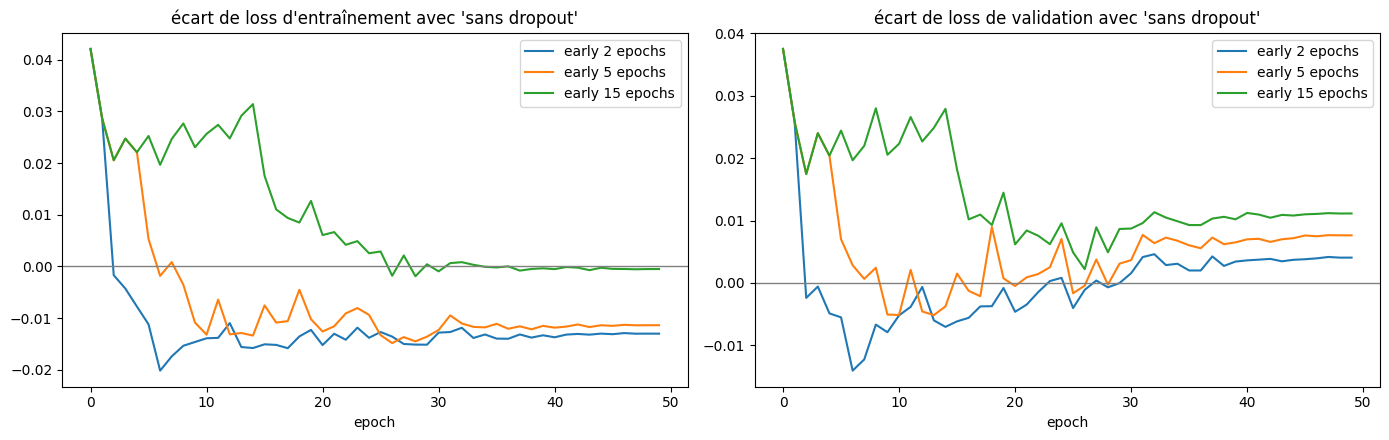

In [181]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for frac in [0.05, 0.1, 0.3]:
    # écart avec le run sans dropout de la même seed, puis moyenne sur les seeds
    ecart = sum(pd.read_csv(fichier("mlp_fmnist", 16, 50, frac, s))[["train_loss", "val_loss"]]
                - pd.read_csv(fichier("mlp_fmnist", 16, 50, 0, s))[["train_loss", "val_loss"]] for s in SEEDS) / len(SEEDS)
    axes[0].plot(ecart.train_loss, label=f"early {round(frac * 50)} epochs")
    axes[1].plot(ecart.val_loss, label=f"early {round(frac * 50)} epochs")
axes[0].set_title("écart de loss d'entraînement avec 'sans dropout'")
axes[1].set_title("écart de loss de validation avec 'sans dropout'")
for ax in axes:
    ax.axhline(0, color="gray", lw=1)
    ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

Pendant la phase de dropout le modèle est en retard (écart positif), puis dès qu'on coupe il passe **devant** et garde une loss d'entraînement plus basse jusqu'à la fin : c'est le comportement décrit dans l'annexe G du papier.

Mais la loss de validation, elle, n'est en dessous que jusqu'au milieu de l'entraînement, puis elle repasse au-dessus. Le modèle avec early dropout apprend plus vite, donc il arrive aussi plus tôt au moment où continuer à apprendre le train ne sert plus à la validation : c'est le léger surapprentissage vu juste au-dessus (minimum vers l'epoch 25, contre 47 sans dropout). Sur 50 epochs, l'ajustement gagné part dans l'écart train/validation.

Si c'est ça, le résultat devrait dépendre du budget : sur un entraînement plus court, l'early dropout devrait aider aussi la validation.

---
## 3. Est-ce que ça dépend du nombre d'epochs ?

On refait la grille sur un budget de 20 epochs : le même MLP (largeur 16, valide aussi à 20 epochs), et le CNN largeur 8 (l'autre case valide de la calibration). À 20 epochs les durées font 1, 2, 4, 6 et 10 epochs.

In [ ]:
for frac in EARLY_GRID:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 20, frac, seed)

gains("mlp_fmnist", 16, 20, EARLY_GRID[1:], SEEDS)

In [183]:
for frac in EARLY_GRID:
    for seed in SEEDS:
        lancer("cnn_fmnist", 8, 20, frac, seed)

gains("cnn_fmnist", 8, 20, EARLY_GRID[1:], SEEDS)

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.05,-0.005,0.010,0.004,0.010,-0.196,0.348,-0.304,0.469
0.10,-0.003,0.011,-0.002,0.009,-0.026,0.189,0.096,0.202
0.20,-0.005,0.010,-0.002,0.010,-0.018,0.154,0.206,0.327
0.30,-0.005,0.011,-0.003,0.011,0.112,0.148,0.102,0.403
0.50,0.001,0.010,-0.001,0.008,-0.147,0.111,0.034,0.425
1.00,0.018,0.011,0.008,0.013,-0.488,0.373,-0.341,0.439


**MLP à 20 epochs** : même baisse de loss d'entraînement qu'à 50 epochs (≈ -0.012 à -0.016 pour 1 à 4 epochs de dropout, significative de 1 à 6 epochs). Cette fois la loss de validation **baisse** un peu au lieu de monter (≈ -0.006 pour 2 epochs, à la limite de la significativité), et l'accuracy a tendance à monter : +0.2 pt en validation (pas significatif), +0.4 pt en test (juste significatif, mais c'est une seule ligne parmi beaucoup, à prendre comme une tendance). Ça va dans le sens de l'explication : l'early dropout fait prendre de l'avance, ce qui aide un peu la validation tant que le modèle n'a pas fini de converger (20 epochs), et plus du tout quand il a fini (50 epochs).

Pour relativiser : passer de 20 à 50 epochs sans dropout fait gagner ~0.5 pt de validation, plus que tout ce que fait l'early dropout.

**CNN largeur 8 à 20 epochs** : toujours aucun gain pour l'early, avec cette fois des IC serrés (±0.1 à 0.3 pt d'accuracy de validation) : un effet de quelques dixièmes de point se serait vu. La seule chose significative est une petite perte à 50 % (-0.15 pt). Et avec 5 seeds le dropout classique ne fait perdre que ~0.5 pt : ce réglage est limite, c'est pour ça qu'on confirme toujours le régime sur plus de seeds.

---
## 4. Contrôle : un réglage qui surapprend

Si notre critère de régime a un sens, il doit aussi marcher dans l'autre sens : dans un réglage qui surapprend (MLP largeur 64 et CNN largeur 16 sur 50 epochs, repérés à la calibration), le dropout classique doit aider et l'early ne doit pas faire mieux. On compare sans dropout, early de 5 epochs et dropout classique, sur les 5 seeds.

In [ ]:
for frac in [0, 0.1, 1]:
    for seed in SEEDS:
        lancer("mlp_fmnist", 64, 50, frac, seed)
        lancer("cnn_fmnist", 16, 50, frac, seed)

# valeurs moyennes sur les 5 seeds : 0 = sans dropout, 0.1 = early (5 epochs), 1 = dropout classique
pd.concat({"MLP largeur 64": niveaux("mlp_fmnist", 64, 50, [0, 0.1, 1], SEEDS),
           "CNN largeur 16": niveaux("cnn_fmnist", 16, 50, [0, 0.1, 1], SEEDS)})

In [ ]:
# écarts avec "sans dropout", seed par seed : c'est ce tableau qui dit si un écart est significatif
pd.concat({"MLP largeur 64": gains("mlp_fmnist", 64, 50, [0.1, 1], SEEDS),
           "CNN largeur 16": gains("cnn_fmnist", 16, 50, [0.1, 1], SEEDS)})

Le premier tableau donne les valeurs, le second dit si les écarts sont significatifs. On compare seed par seed parce que la variation entre seeds est du même ordre que les écarts : deux moyennes peuvent avoir des écarts-types qui se chevauchent alors que l'écart apparié est net.

**Ces modèles surapprennent bien** : sans dropout, la loss d'entraînement est très basse (≈ 0.07 sur le MLP, 0.015 sur le CNN) alors que la loss de validation est 6 à 30 fois plus haute.

C'est bien l'inverse du cadre principal : le dropout classique a la **meilleure accuracy** des trois (≈ +0.4 pt de validation et +0.6 pt de test sur le MLP, +0.8 pt sur le CNN, par rapport à sans dropout) et la **loss de validation la plus basse** (nettement, et de façon significative pour les deux modèles). L'ordre attendu est respecté : dropout classique > early ≈ sans dropout. Avec 5 seeds, le gain d'accuracy est significatif sur le CNN et en test sur le MLP (en validation, l'IC du MLP touche tout juste 0). Le critère de régime fonctionne donc dans les deux sens.

**Un point important** : sur le MLP largeur 64, l'early dropout fait aussi baisser la loss d'entraînement (≈ -0.008, sur les 5 seeds, significatif), sans rien gagner en validation. L'effet "le modèle apprend mieux le train" n'est donc pas réservé au sous-apprentissage. Sur le CNN largeur 16, l'early ne change rien de significatif.

---
## 5. Sensibilité au taux de dropout : p = 0.3

L'étude sur CIFAR-10 a tout fait avec p = 0.3. Pour savoir si on peut comparer, on refait nos deux cadres principaux à p = 0.3 sur les durées 0.1, 0.3 et 1. Le run sans dropout ne dépend pas de p, donc on garde la même référence. Les CSV vont dans `resultats/p03/`.

In [186]:
os.makedirs("resultats/p03", exist_ok=True)
for frac in [0.1, 0.3, 1]:
    for seed in SEEDS:
        lancer("mlp_fmnist", 16, 50, frac, seed, p=0.3, dossier="resultats/p03")
        lancer("cnn_fmnist", 4, 50, frac, seed, p=0.3, dossier="resultats/p03")

pd.concat({
    "MLP p=0.1": g_mlp.loc[[0.1, 0.3, 1]],
    "MLP p=0.3": gains("mlp_fmnist", 16, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03"),
    "CNN p=0.1": g_cnn.loc[[0.1, 0.3, 1]],
    "CNN p=0.3": gains("cnn_fmnist", 4, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03"),
})

train_loss  ic_train_loss  val_loss  ic_val_loss  val_acc  \
MLP p=0.1 0.1      -0.011          0.002     0.008        0.006   -0.106   
          0.3      -0.001          0.003     0.011        0.006   -0.378   
          1.0       0.039          0.004     0.024        0.007   -1.095   
MLP p=0.3 0.1      -0.008          0.009     0.007        0.008   -0.065   
          0.3       0.015          0.012     0.016        0.007   -0.484   
          1.0       0.128          0.013     0.094        0.009   -2.923   
CNN p=0.1 0.1       0.005          0.012     0.007        0.018   -0.408   
          0.3      -0.005          0.013    -0.002        0.018   -0.155   
          1.0       0.037          0.022     0.025        0.019   -1.412   
CNN p=0.3 0.1      -0.001          0.025    -0.001        0.024   -0.208   
          0.3       0.002          0.033     0.003        0.023   -0.302   
          1.0       0.111          0.056     0.090        0.043   -3.977   

               ic_val_acc  test_acc  ic_test_acc  
MLP p=0.1 0.1       0.326     0.119        0.438  
          0.3       0.383    -0.096        0.307  
          1.0       0.238    -0.687        0.301  
MLP p=0.3 0.1       0.329     0.066        0.576  
          0.3       0.472    -0.275        0.233  
          1.0       0.583    -2.465        0.397  
CNN p=0.1 0.1       0.966    -0.253        0.795  
          0.3       1.025    -0.015        0.808  
          1.0       1.179    -1.109        1.016  
CNN p=0.3 0.1       0.987    -0.090        1.077  
          0.3       0.864    -0.292        1.032  
          1.0       1.276    -3.642        1.510

- **Dropout classique** : à p = 0.3 il fait beaucoup plus mal (-2.9 pt sur le MLP, -4.0 pt sur le CNN, contre -1.1 et -1.4 à p = 0.1). Pour nos tout petits modèles, 0.3 tout le long est trop fort.
- **Early court (10 %)** : pareil qu'à p = 0.1, accuracy inchangée, loss d'entraînement un peu plus basse sur le MLP (pas significatif ici).
- **Early 30 %** : à p = 0.1 la perte n'était pas significative (-0.4 pt), à p = 0.3 elle le devient (-0.5 pt sur le MLP) et la loss d'entraînement finit plus haute au lieu de plus basse. Plus le taux est fort, plus il faut couper tôt.

Donc les conclusions restent les mêmes à p = 0.3, mais la fenêtre utile rétrécit : on ne compare les **durées** avec CIFAR-10 qu'à p égal.

**Est-ce que c'est juste la quantité totale de dropout qui compte ?** Sur le MLP, 15 epochs à p = 0.1 et 5 epochs à p = 0.3 font la même "dose" (p × durée). Pourtant le deuxième a l'air meilleur : loss d'entraînement -0.008 contre -0.001, accuracy -0.07 contre -0.38. Ce n'est qu'une comparaison, et le point à p = 0.3 n'est pas significatif lui-même : c'est une **tendance**, qui suggère que le fait d'être tôt compte, pas seulement la quantité totale de dropout.

### La position du dropout

Autre différence avec CIFAR-10 : eux ont un seul dropout, juste avant la couche de sortie. On teste cette position sur notre MLP (on enlève le premier dropout), à p = 0.3.

In [187]:
def mlp_tete(L):
    model, opt = mlp(784, 10, couche_cache=L)
    model[2] = nn.Identity()          # on enlève le 1er dropout : il reste seulement celui avant la sortie
    return model, opt

CADRES["mlp_tete_fmnist"] = (mlp_tete, vecteurs)

for frac in [0.1, 0.3, 1]:
    for seed in SEEDS:
        lancer("mlp_tete_fmnist", 16, 50, frac, seed, p=0.3, dossier="resultats/p03")

# sans dropout ce modèle est le même que le MLP normal, donc même référence
gains("mlp_tete_fmnist", 16, 50, [0.1, 0.3, 1], SEEDS, dossier="resultats/p03", reference="mlp_fmnist")

,train_loss,ic_train_loss,val_loss,ic_val_loss,val_acc,ic_val_acc,test_acc,ic_test_acc
0.1,-0.003,0.007,0.005,0.009,-0.065,0.313,0.243,0.382
0.3,0.005,0.007,0.011,0.009,-0.247,0.353,0.143,0.425
1.0,0.035,0.008,0.030,0.008,-0.879,0.385,-0.482,0.382


Un seul dropout à 0.3 avant la sortie fait perdre ~0.9 pt en dropout classique, à peu près comme nos deux dropouts à 0.1 (-1.1 pt). Leur réglage est donc une intervention de force comparable à notre réglage principal, et l'early n'y a pas plus d'effet sur l'accuracy.

### La position du dropout à faible dose (p = 0.1)

Le test à faible dose demandé au groupe CIFAR-10 (p = 0.1, early court) se fera avec **leur** position : un seul dropout avant la sortie. Notre baisse de loss d'entraînement, elle, a été vue avec **nos** deux dropouts. Si leur test ne montre rien, il faut savoir si c'est à cause du jeu de données ou de la position. On refait donc nos durées courtes (2, 5 et 10 epochs) avec le MLP à un seul dropout, à p = 0.1, plus le dropout classique pour vérifier que ce MLP est toujours en sous-apprentissage. Mêmes seeds et même référence sans dropout (sans dropout, les deux MLP sont identiques).

In [ ]:
for frac in [0.05, 0.1, 0.2, 1]:
    for seed in SEEDS:
        lancer("mlp_tete_fmnist", 16, 50, frac, seed)        # p = 0.1, CSV dans resultats/

pd.concat({"2 dropouts (notre MLP)": g_mlp.loc[[0.05, 0.1, 0.2, 1]],
           "1 dropout avant la sortie": gains("mlp_tete_fmnist", 16, 50, [0.05, 0.1, 0.2, 1], SEEDS, reference="mlp_fmnist")})

Avec un seul dropout avant la sortie (la position du groupe CIFAR-10), à p = 0.1, la loss d'entraînement baisse encore mais **deux fois moins** (≈ -0.006 au lieu de -0.011 à -0.013 avec nos deux dropouts), et ce n'est plus significatif : 4 seeds sur 5 vont dans ce sens, mais les IC contiennent 0. Le dropout classique n'y fait presque plus perdre (-0.3 pt de validation, sous notre seuil de 0.5 pt) : un seul dropout léger ne met plus le modèle en sous-apprentissage.

Donc **la position compte** : avec un seul dropout léger, l'effet devient trop petit pour être vu avec 5 seeds. Si le groupe CIFAR-10 garde cette position, une absence d'effet chez eux ne contredirait pas nos résultats ; pour comparer, il faut placer le dropout au même endroit (après chaque couche ou bloc).

---
## 6. Q3 : le "début" se compte-t-il en epochs ou en itérations ?

Le papier règle la durée en epochs, mais le modèle avance par itérations (pas de gradient). À batch 128, une epoch = 391 itérations. On refait la grille du MLP largeur 16 (50 epochs, 5 seeds) avec un batch **4 fois plus petit (32)** et **4 fois plus grand (512)**, tout le reste identique (même lr) ; la référence sans dropout est celle du même batch. Les runs ont été faits avec `q3_epochs_vs_iterations.ipynb` (Colab), les CSV sont dans `resultats/batch32/` et `resultats/batch512/`.

| batch | itérations par epoch | 1 epoch de dropout = |
|---|---|---|
| 32 | 1 563 | 4 epochs à batch 128 |
| 128 | 391 | (référence) |
| 512 | 98 | 1/4 d'epoch à batch 128 |

À batch 128, la baisse de loss d'entraînement est forte de 1 à 5 epochs de dropout et disparaît vers 15. Si le début se compte en epochs, la courbe reste la même pour les trois batchs. Si c'est en itérations, la fenêtre s'allonge (en epochs) à batch 512 et raccourcit à batch 32.

**Deux comparaisons fixées avant les runs** : batch 512 avec 15 epochs de dropout (rien si c'est en epochs, baisse si c'est en itérations) et batch 32 avec 5 epochs (baisse si c'est en epochs, rien si c'est en itérations).

In [ ]:
BATCHS_Q3 = [32, 128, 512]
ITER_PAR_EPOCH = {b: int(np.ceil(len(vecteurs["Xtr"]) / b)) for b in BATCHS_Q3}

def dossier_batch(b):
    return "resultats" if b == BATCH else f"resultats/batch{b}"     # batch 128 = la grille principale

def avec_durees(g, b, E=50):
    # ajoute la durée du dropout en epochs et en itérations
    g = g.copy()
    g.insert(0, "epochs", [round(f * E) for f in g.index])
    g.insert(1, "iterations", g.epochs * ITER_PAR_EPOCH[b])
    return g

q3_mlp = {b: avec_durees(gains("mlp_fmnist", 16, 50, DUREES, SEEDS, dossier=dossier_batch(b), dossier_ref=dossier_batch(b)), b)
          for b in BATCHS_Q3}
pd.concat({f"batch {b}": g for b, g in q3_mlp.items()})

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for b, g in q3_mlp.items():
    g = g.drop(index=1)                                    # le dropout classique n'est pas un early
    for ax, x in zip(axes, ["epochs", "iterations"]):
        ax.errorbar(g[x], g.train_loss, yerr=g.ic_train_loss, marker="o", capsize=4, label=f"batch {b}")
for ax, x in zip(axes, ["epochs", "itérations"]):
    ax.set_xscale("log"); ax.axhline(0, color="gray", lw=1); ax.legend()
    ax.set_xlabel(f"durée du dropout en {x}"); ax.set_ylabel("écart de loss d'entraînement")
    ax.set_title(f"MLP largeur 16 : écart avec 'sans dropout' selon la durée en {x}")
plt.tight_layout(); plt.show()

for b, frac in [(512, 0.3), (32, 0.1)]:
    r = q3_mlp[b].loc[frac]
    print(f"batch {b}, early {r.epochs:.0f} epochs : écart de loss d'entraînement {r.train_loss:+.4f} ± {r.ic_train_loss:.4f}")

**Le régime ne change pas** : à chaque batch le dropout classique fait perdre environ 1 pt de validation (ligne 1.0), le MLP reste en sous-apprentissage.

**Les deux comparaisons fixées d'avance vont du côté des itérations** :
- batch 512, 15 epochs de dropout : la loss d'entraînement baisse encore (≈ -0.012, sur les 5 seeds, significatif), alors qu'à batch 128 il n'y a plus rien à 15 epochs ;
- batch 32, 5 epochs : plus rien (≈ +0.002), alors qu'à batch 128 c'est un des meilleurs points.

Plus largement, à batch 512 la fenêtre utile va de 1 à 15 epochs (maximum vers 5-10 epochs, ≈ -0.018) et à batch 32 il n'y a de baisse à aucune durée : dès 10 epochs l'early fait même **monter** la loss d'entraînement, comme un dropout long.

**Mais ce n'est pas une simple règle en itérations** : sur la figure de droite, les courbes des batchs 128 et 512 se rapprochent, mais pas celle du batch 32. À batch 32, 1 epoch (1 563 itérations) ne fait rien, alors que le même nombre d'itérations donne ≈ -0.012 aux deux autres batchs. Ce qui change aussi, c'est l'**ampleur** de l'effet : -0.018 à batch 512, -0.013 à batch 128, rien à batch 32. Or plus le batch est petit, plus le modèle fait de pas et mieux il a appris à la fin (loss d'entraînement sans dropout ≈ 0.29, 0.25 et 0.21) : il reste moins à gagner.

À batch 512, l'early aide même un peu la généralisation : la loss de validation baisse (≈ -0.01 pour 5 et 10 epochs, significatif) et l'accuracy de test gagne ≈ +0.3 pt (significatif seulement à 10 epochs). C'est le même phénomène qu'à 20 epochs (section 3) : moins le modèle a convergé, plus l'avance prise grâce à l'early dropout se voit en validation.

In [ ]:
# CNN largeur 4 (10 seeds) : batch 128 (grille principale) et batch 512. Le batch 32 a été abandonné.
q3_cnn = {b: avec_durees(gains("cnn_fmnist", 4, 50, [0.05, 0.1, 0.2, 0.3, 1], SEEDS_CNN,
                               dossier=dossier_batch(b), dossier_ref=dossier_batch(b)), b)
          for b in [128, 512]}
print("accuracy de validation sans dropout :",
      {b: round(np.mean([fin_de_run(fichier("cnn_fmnist", 4, 50, 0, s, dossier_batch(b))).val_acc for s in SEEDS_CNN]) * 100, 1)
       for b in [128, 512]})
pd.concat({f"batch {b}": g for b, g in q3_cnn.items()})

**CNN à batch 512 : le plus gros effet de toute l'étude.** Un early de 5 à 15 epochs fait baisser la loss d'entraînement (≈ -0.03 à -0.045) **et** la loss de validation, et gagne **+1.1 à +1.5 pt** d'accuracy de validation (+1.0 à +1.4 pt en test), sur 9 ou 10 seeds sur 10, avec des IC loin de 0. Epoch par epoch, le modèle avec early dropout passe devant dès qu'on coupe le dropout et garde son avance jusqu'à la fin.

Pourquoi ici ? À batch 512 le CNN ne fait que 4 900 pas : il est loin d'avoir convergé (≈ 83 % de validation sans dropout, contre 88 % à batch 128, et la loss baisse encore à la fin). Le dropout classique, lui, ne fait plus perdre (≈ -0.3 pt, pas significatif) : notre critère de régime ne classe donc **pas** ce réglage en sous-apprentissage, alors que c'est là que l'early dropout aide le plus. Le manque d'apprentissage vient ici du budget (trop peu de pas), pas de la taille du modèle.

Pour Q3, le CNN ne va **pas** du côté des itérations : si c'était en itérations, la fenêtre de batch 128 (10-15 epochs) devrait passer à 40 epochs ou plus à batch 512 ; elle reste à 5-15 epochs.

**Réponse à Q3** : pas de règle simple. Sur le MLP les deux tests fixés d'avance donnent raison aux itérations, sur le CNN la fenêtre ne bouge pas en epochs. Le résultat le plus net est ailleurs : **plus le modèle est loin d'avoir convergé à la fin (gros batch, peu de pas), plus l'early dropout aide**, jusqu'à améliorer l'accuracy. La limite de cette expérience : à 50 epochs fixes, changer le batch change à la fois "l'horloge" et le nombre total de pas, donc le régime. Pour séparer les deux, on refait le batch 512 sur 200 epochs, soit le même nombre de pas qu'à batch 128 sur 50 epochs (ci-dessous).

### Même nombre de pas : batch 512 sur 200 epochs

À 50 epochs, passer de batch 128 à batch 512 change deux choses à la fois : la taille du batch et le nombre total de pas (19 550 contre 4 900). On refait donc le batch 512 sur **200 epochs**, soit 19 550 pas comme à batch 128 sur 50 epochs : seule la taille du batch change encore. Même protocole qu'avant (même lr, cosinus sur les 200 epochs), MLP largeur 16 sur 5 seeds et CNN largeur 4 sur 10 seeds, avec des durées choisies pour départager epochs et itérations (1, 2, 5, 10, 20, 40 et 60 epochs de dropout ; le CNN commence à 5). Les runs se font avec `q3_epochs_vs_iterations.ipynb` (section 3), tous sur la même machine, et la référence sans dropout est celle de batch 512 sur 200 epochs.

**Prédictions, écrites avant les runs.**

*Gain d'accuracy (le message de l'étude)*. Si le gain de batch 512 vient du manque de pas, il disparaît quand on donne autant de pas qu'à batch 128 :
- **confirmé** si, sur le CNN, le meilleur gain de validation parmi les durées early tombe sous 0.5 pt avec un IC qui contient 0 (contre +1.5 pt à 50 epochs), et si le MLP n'a plus de gain de test significatif ;
- **réfuté** si le CNN garde au moins 1 pt avec un IC entièrement positif : ce serait alors la taille du batch elle-même qui compte.

*Horloge (Q3), sur la loss d'entraînement du MLP*. À batch 512, 1 epoch = 98 itérations, donc 20 epochs ≈ 1 960 itérations ≈ 5 epochs à batch 128 :
- comparaison principale, early de **20 epochs** : baisse nette (≈ -0.01) si ça se compte en itérations ; rien, ou une hausse, si ça se compte en epochs ;
- comparaison secondaire, early de **1 epoch** : baisse (≈ -0.009, comme 1 epoch à batch 128) si c'est en epochs ; à peu près rien si c'est en itérations.

Sur le CNN, la fenêtre de batch 128 (10-15 epochs, soit 3 900 à 5 900 itérations) devrait passer à 40-60 epochs si c'est en itérations, et rester vers 10 epochs si c'est en epochs.

In [ ]:
# runs faits avec q3_epochs_vs_iterations.ipynb (section 3), CSV dans resultats/batch512/
DUREES_200 = {"mlp_fmnist": [0.005, 0.01, 0.025, 0.05, 0.1, 0.2, 0.3, 1],     # 1, 2, 5, 10, 20, 40, 60 epochs, classique
              "cnn_fmnist": [0.025, 0.05, 0.1, 0.2, 0.3, 1]}                 # 5, 10, 20, 40, 60 epochs, classique
SEEDS_200 = {"mlp_fmnist": SEEDS, "cnn_fmnist": SEEDS_CNN}
LARGEUR = {"mlp_fmnist": 16, "cnn_fmnist": 4}

def runs_faits(cadre):
    return all(os.path.exists(fichier(cadre, LARGEUR[cadre], 200, f, s, "resultats/batch512"))
               for f in [0] + DUREES_200[cadre] for s in SEEDS_200[cadre])

q3_200 = {}
for cadre in ["mlp_fmnist", "cnn_fmnist"]:
    if runs_faits(cadre):
        g = gains(cadre, LARGEUR[cadre], 200, DUREES_200[cadre], SEEDS_200[cadre],
                  dossier="resultats/batch512", dossier_ref="resultats/batch512")
        q3_200[cadre] = avec_durees(g, 512, E=200)
    else:
        print(cadre, ": les runs batch 512 sur 200 epochs ne sont pas encore tous faits")

pd.concat(q3_200) if q3_200 else None

In [ ]:
# les trois réglages sur le même axe (durée du dropout en itérations) : 128/50 et 512/200 ont le même nombre de pas
if q3_200:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    reglages = {"mlp_fmnist": [("batch 128, 50 epochs", q3_mlp[128]), ("batch 512, 50 epochs", q3_mlp[512])],
                "cnn_fmnist": [("batch 128, 50 epochs", q3_cnn[128]), ("batch 512, 50 epochs", q3_cnn[512])]}
    graphes = [("mlp_fmnist", "train_loss", "MLP : écart de loss d'entraînement"),
               ("cnn_fmnist", "val_acc", "CNN : gain d'accuracy de validation (points)")]
    for ax, (cadre, m, titre) in zip(axes, graphes):
        courbes = reglages[cadre] + ([("batch 512, 200 epochs", q3_200[cadre])] if cadre in q3_200 else [])
        for nom, g in courbes:
            g = g.drop(index=1)                            # le dropout classique n'est pas un early
            ax.errorbar(g.iterations, g[m], yerr=g["ic_" + m], marker="o", capsize=4, label=nom)
        ax.set_xscale("log"); ax.axhline(0, color="gray", lw=1); ax.legend()
        ax.set_xlabel("durée du dropout en itérations"); ax.set_title(titre)
    plt.tight_layout(); plt.show()

    # les comparaisons fixées avant les runs
    if "mlp_fmnist" in q3_200:
        for frac, quoi in [(0.1, "early 20 epochs (1 960 itérations)"), (0.005, "early 1 epoch (98 itérations)")]:
            r = q3_200["mlp_fmnist"].loc[frac]
            print(f"MLP {quoi} : écart de loss d'entraînement {r.train_loss:+.4f} ± {r.ic_train_loss:.4f}")
        r = q3_200["mlp_fmnist"].drop(index=1)
        print(f"MLP meilleur gain de test parmi les durées early : {r.test_acc.max():+.2f} pt")
    if "cnn_fmnist" in q3_200:
        g = q3_200["cnn_fmnist"].drop(index=1)
        r = g.loc[g.val_acc.idxmax()]
        print(f"CNN meilleur gain de validation (early {r.epochs:.0f} epochs) : {r.val_acc:+.2f} ± {r.ic_val_acc:.2f} pt")
    for cadre, g in q3_200.items():
        print(f"régime {cadre} : dropout classique {g.loc[1].val_acc:+.2f} ± {g.loc[1].ic_val_acc:.2f} pt de validation")

**Résultat** : à écrire une fois les runs faits, en suivant les prédictions ci-dessus (confirmé ou réfuté, sans changer les critères après coup).

---
## Conclusion pour Fashion-MNIST


**Q1 — est-ce que l'early dropout marche à notre échelle ?**
- *En partie sur le MLP* : un early dropout court fait baisser la loss d'entraînement finale de façon nette et répétable (≈ -0.013, à 20 comme à 50 epochs). Le mécanisme du papier ("le modèle apprend mieux") se retrouve donc sur un MLP de 13 000 paramètres.
- *Mais pas sur la généralisation* : aucun gain d'accuracy significatif à batch 128, dans aucun réglage (l'exception est le batch 512, voir Q3). La loss de validation s'améliore un peu sur un budget court (20 epochs) et se dégrade un peu sur un budget long (50 epochs) : l'early dropout fait surtout prendre de l'avance au modèle.
- *L'effet sur la loss d'entraînement n'est pas propre au sous-apprentissage* : il apparaît aussi, de façon significative, dans le MLP qui surapprend (contrôle, 5 seeds), et reste en tendance avec un seul dropout qui ne met plus le modèle en sous-apprentissage (test de position). C'est plutôt un effet sur l'optimisation, alors que le papier le relie au sous-apprentissage.
- *Sur le CNN, un effet plus tardif et plus fragile* : avec 10 seeds, la loss d'entraînement baisse aussi, mais pour un early de 10 à 15 epochs (20-30 %) et pas pour 1 ou 2 epochs. C'est significatif pris seul, mais ça ne résiste pas à la correction de Holm (de peu). Aucun gain d'accuracy, et on ne voit pas les effets plus petits que ~0.7 pt. Son régime est en plus limite (le dropout classique ne fait presque plus perdre sur des seeds neuves).

**Q2 — quelle durée ?**
- Sur le MLP, le plus court est le mieux : de 1 à 5 epochs (2 à 10 % de l'entraînement) l'effet est comparable (on ne peut pas les départager), puis il diminue régulièrement quand on allonge, disparaît vers 30 %, et à partir de 50 % l'early dropout se comporte comme du dropout classique.
- Sur le CNN c'est l'inverse : rien à 1-2 epochs, une tendance à 10-15 epochs. Le bon moment pour couper le dropout dépend donc du modèle ; une durée unique en % de l'entraînement ne marche pas pour les deux.
- La plage "de 1 % à 50 %" du papier ne tient donc pas à notre échelle, et elle rétrécit encore quand le taux augmente (à p = 0.3, 30 % fait déjà perdre).
- À quantité de dropout égale, court et fort a l'air de valoir mieux que long et faible sur le MLP (une seule comparaison, non significative) : c'est une tendance qui va dans le sens de "early = au tout début".

**Q3 — epochs ou itérations ?**
- Sur le MLP, les deux comparaisons fixées d'avance vont du côté des itérations : avec un batch 4 fois plus gros, 15 epochs de dropout marchent encore ; avec un batch 4 fois plus petit, 5 epochs ne font plus rien.
- Mais les courbes ne se superposent pas vraiment en itérations (le batch 32 ne suit pas), et sur le CNN la fenêtre ne bouge pas en epochs. Pas de règle simple.
- Le plus net : plus le modèle est loin d'avoir convergé à la fin (gros batch, peu de pas), plus l'early dropout aide. À batch 512 il améliore la généralisation : ≈ +0.3 pt de test sur le MLP et +1 à +1.5 pt de validation et de test sur le CNN, le plus gros gain de l'étude. C'est l'esprit du papier (l'early dropout aide un modèle qui n'apprend pas assez), mais ce manque vient ici du budget d'entraînement, et notre critère "le dropout classique fait perdre" ne le détecte pas.
- Le test à nombre de pas égal (batch 512 sur 200 epochs) dira si ce gain vient bien du manque de pas : à compléter avec ses résultats.

**Ce qui rend ces résultats crédibles** : le régime du MLP est confirmé sur des seeds qui n'ont pas servi à le choisir, la baisse de loss d'entraînement résiste à une correction pour comparaisons multiples (Holm), et le contrôle en surapprentissage donne bien l'inverse (le dropout classique y améliore nettement la loss de validation et l'accuracy, l'early non).

**Limites** :
- Nombre de seeds : on ne voit que les effets d'accuracy plus grands que ~0.45 pt sur le MLP (5 seeds) et ~0.7 pt sur le CNN largeur 4 (10 seeds). "Pas détecté" ne veut pas dire "nul".
- Le régime du CNN largeur 4 est limite : sur des seeds neuves le dropout classique ne fait presque plus perdre. Les conclusions sur le CNN sont donc plus fragiles que sur le MLP.
- Un seul jeu de données, des modèles 1000 fois plus petits que ceux du papier, pas d'augmentation (le papier en utilise beaucoup, ce qui crée du sous-apprentissage d'une autre façon).
- Q3 : à 50 epochs fixes, changer le batch change aussi le nombre total de pas, donc le régime ; le test batch 512 sur 200 epochs sert à séparer les deux. Le CNN à batch 32 a été abandonné.